In [116]:
import numpy as np
import matplotlib.pyplot as plt

# Завдання 1. Оцінка площі чверті кола методом Монте-Карло для Варіанта 1 (Київ)
np.random.seed(1)
N = 1000

# Генерація випадкових координат x та y рівномірно на [0, 1]
x = np.random.uniform(0, 1, size=N)
y = np.random.uniform(0, 1, size=N)

# Умова приналежності точки чверті кола: x^2 + y^2 <= 1
inside = (x**2 + y**2) <= 1

# Частка точок всередині фігури
fraction = inside.mean()

# Площа прямокутника-охоплення (квадрат [0,1]x[0,1] має площу 1)
rect_area = 1.0
mc_estimate = fraction * rect_area

exact_value = np.pi / 4

print(f"Кількість випробувань (N): {N}")
print(f"Оцінка площі методом Монте-Карло: {mc_estimate:.4f}")
print(f"Точне аналітичне значення (π/4): {exact_value:.4f}")

Кількість випробувань (N): 1000
Оцінка площі методом Монте-Карло: 0.7700
Точне аналітичне значення (π/4): 0.7854


In [117]:
# Завдання 2. Порівняння з точним значенням
absolute_error = abs(mc_estimate - exact_value)
relative_error_pct = (absolute_error / exact_value) * 100

print(f"Абсолютна похибка: {absolute_error:.4f}")
print(f"Відносна похибка: {relative_error_pct:.2f}%")

Абсолютна похибка: 0.0154
Відносна похибка: 1.96%


In [118]:
# Завдання 3. Дослідження збіжності за кількістю випробувань
np.random.seed(1)
n_values = [100, 1_000, 10_000, 100_000]
mean_errors = []

for n in n_values:
    errors = []
    for _ in range(200):
        x_sim = np.random.uniform(0, 1, size=n)
        y_sim = np.random.uniform(0, 1, size=n)
        fraction_sim = ((x_sim**2 + y_sim**2) <= 1).mean()
        estimate = fraction_sim * 1.0
        errors.append(abs(estimate - exact_value))

    avg_error = np.mean(errors)
    mean_errors.append(avg_error)
    print(f"N = {n:7d} | Середня абсолютна похибка: {avg_error:.5f}")

N =     100 | Середня абсолютна похибка: 0.03500
N =    1000 | Середня абсолютна похибка: 0.01036
N =   10000 | Середня абсолютна похибка: 0.00334
N =  100000 | Середня абсолютна похибка: 0.00106


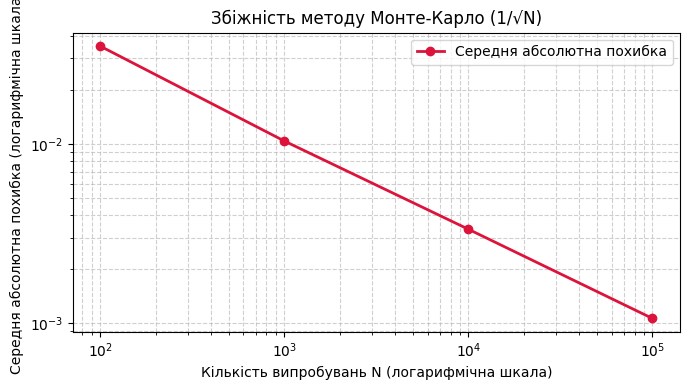

In [119]:
# Завдання 4. Графік залежності похибки від N
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(n_values, mean_errors, marker='o', color='crimson', linewidth=2, label='Середня абсолютна похибка')
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Кількість випробувань N (логарифмічна шкала)")
ax.set_ylabel("Середня абсолютна похибка (логарифмічна шкала)")
ax.set_title("Збіжність методу Монте-Карло (1/√N)")
ax.grid(True, which="both", linestyle="--", alpha=0.6)
ax.legend()

plt.tight_layout()
plt.show()

### Відповіді на контрольні запитання:

1. **Чому оцінка Монте-Карло є вибірковим середнім і що гарантує її збіжність:**
   - Оцінка формується як частка (середнє значення бінарних індикаторів 0/1 або значень функції у випадкових точках). Закон великих чисел гарантує, що з ростом $N$ це вибіркове середнє прямує до істинного математичного сподівання (точної площі чи інтеграла).

2. **Чому вчетверо більша кількість випробувань дає лише вдвічі меншу похибку:**
   - Через наявність квадратного кореня в знаменнику формули стандартної похибки ($\text{SE} \sim \frac{1}{\sqrt{N}}$). Щоб зменшити похибку вдвічі, розмір випробувань потрібно збільшити у $2^2 = 4$ рази.

3. **Для варіанта типу «площа»: чому частку точок множать саме на площу прямокутника-охоплення:**
   - Метод Монте-Карло оцінює безрозмірну *частку* площі фігури відносно площі відомої навколишньої області. Щоб отримати абсолютне значення площі самої фігури, цю частку необхідно помножити на загальну площу охоплюючого прямокутника.

4. **Для варіанта типу «сподівання»: чому використовують `.min(axis=1)` або `.max(axis=1)`:**
   - Параметр `axis=1` змушує функцію рахувати мінімум чи максимум окремо для кожного рядка матриці (тобто для кожного окремого незалежного експерименту/випробування), перетворюючи матрицю кидків на масив зведених результатів випробувань, а не згортаючи всю матрицю в єдине число.